# 01 V2 — Clean RAW EDA, source lineage, frozen train/val/test

CPU-only. Chỉ đọc `clean_raw_14_person_11n_pt_v001.zip`. V1 giữ nguyên.

## 1 — Cấu hình và xác minh ZIP (CPU)
Dùng tên ZIP mới; không đụng file V1. `POSEFORGE_ROOT`/`POSEFORGE_ZIP` tùy chọn khi chạy local.

In [1]:
from pathlib import Path
import os,sys,json,zipfile,io,hashlib,tempfile,shutil
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
DRIVE_ROOT = Path('/content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu')
ROOT = Path(os.environ['POSEFORGE_ROOT']).expanduser() if os.environ.get('POSEFORGE_ROOT') else (
    DRIVE_ROOT if DRIVE_ROOT.is_dir() else next(
        (p for p in (Path.cwd(),*Path.cwd().parents) if (p/'notebooks').is_dir() and (p/'shared').is_dir()), Path.cwd()))
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from shared.dataset_pipeline import scan_raw_zip, file_sha256, COCO13
from shared.pose_training import read_clean_lineage, frozen_split, dataset_output_root, refresh_review_zip, LABELS
from shared.pose_features import CausalPoseNormalizer, FEATURE_VERSION, FEATURE_SHAPE, CONFIDENCE_THRESHOLD
RAW_ZIP = Path(os.environ.get('POSEFORGE_ZIP', ROOT/'raw_dataset_zip/clean_raw_14_person_11n_pt_v001.zip'))
SEED = 302
VAL_PEOPLE = ['TDUY','DGD']
TEST_PEOPLE = ['TRUONG']
assert RAW_ZIP.is_file(),f'Missing {RAW_ZIP}'
SOURCE_SHA = file_sha256(RAW_ZIP)
BASE = dataset_output_root(ROOT,SOURCE_SHA)
BASE.mkdir(parents=True,exist_ok=True)
RAW_REPORT = BASE/'raw'

def stage_zip(source, sha):
    if not Path('/content').is_dir() or not str(source.resolve()).startswith('/content/drive/'):
        return source
    dst=Path('/content')/f'poseforge_{sha[:12]}.zip'
    if not dst.is_file() or file_sha256(dst) != sha:
        with source.open('rb') as f, dst.open('wb') as o, tqdm(total=source.stat().st_size,unit='B',unit_scale=True,desc='Stage ZIP') as p:
            while (chunk:=f.read(4*1024*1024)):
                o.write(chunk);p.update(len(chunk))
    assert file_sha256(dst)==sha
    return dst

LOCAL_ZIP=stage_zip(RAW_ZIP,SOURCE_SHA)
print('ROOT:',ROOT,'\nDATASET:',RAW_ZIP.name,'\nSHA256:',SOURCE_SHA)

Mounted at /content/drive


Stage ZIP:   0%|          | 0.00/528M [00:00<?, ?B/s]

ROOT: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu 
DATASET: clean_raw_14_person_11n_pt_v001.zip 
SHA256: 41774c321098e08e1103a63cd5b64e31a3a6d7e293fff30472a6cebdad919384


## 2 — Đọc YOLO17, kiểm tra số lượng và lineage
Từng segment đã trim vẫn tham chiếu `source_take_id` gốc. Chặn thiếu/đè source frame.

In [2]:
catalog,frame_quality,joint_coverage,examples,audit=scan_raw_zip(LOCAL_ZIP,CONFIDENCE_THRESHOLD)
assert not audit['issues'],f"Structural/provenance issues: {audit['issues'][:10]}"
lineage,curation=read_clean_lineage(LOCAL_ZIP,catalog)
catalog=catalog.merge(lineage,on='clip_id',validate='one_to_one')
assert catalog.clip_id.is_unique and len(catalog)==206
assert catalog.person_id.nunique()==14 and catalog.label.nunique()==6
assert int(catalog.frames.sum())==21996
assert catalog.pose_model.eq('yolo11n-pose.pt').all()
assert len(frame_quality)==int(catalog.frames.sum())
print(f"{len(catalog)} clips | {catalog.drop_duplicates(['person_id','session_id','label','take_id']).shape[0]} exported takes | {catalog.person_id.nunique()} people | {int(catalog.frames.sum())} frames")
print('Pose17:',int(catalog.pose17_frames.sum()),'| Full 13:',int(catalog.full13_frames.sum()),'| Missing:',int(catalog.frames.sum()-catalog.pose17_frames.sum()))
print('Excluded takes:',curation.get('excluded_source_takes',[]))
display(catalog[['person_id','label','camera_id','frames','source_group_id','source_segment','pose17_rate']].head(10))

Scan YOLO17 clip-camera:   0%|          | 0/206 [00:00<?, ?clip/s]

206 clips | 103 exported takes | 14 people | 21996 frames
Pose17: 21987 | Full 13: 8005 | Missing: 9
Excluded takes: ['DPHI/session_20261029_1142/label_0/take_001', 'DPHI/session_20261029_1142/label_0/take_002']


,person_id,label,camera_id,frames,source_group_id,source_segment,pose17_rate
0,CHANH,0,cam01,71,CHANH/session_20261027_1124/label_0/CHANH_sess...,0,1.0
1,CHANH,0,cam02,71,CHANH/session_20261027_1124/label_0/CHANH_sess...,0,1.0
2,CHANH,1,cam01,73,CHANH/session_20261027_1124/label_1/CHANH_sess...,0,1.0
3,CHANH,1,cam02,73,CHANH/session_20261027_1124/label_1/CHANH_sess...,0,1.0
4,CHANH,2,cam01,68,CHANH/session_20261027_1124/label_2/CHANH_sess...,0,1.0
5,CHANH,2,cam02,69,CHANH/session_20261027_1124/label_2/CHANH_sess...,0,1.0
6,CHANH,3,cam01,75,CHANH/session_20261027_1124/label_3/CHANH_sess...,0,1.0
7,CHANH,3,cam02,74,CHANH/session_20261027_1124/label_3/CHANH_sess...,0,1.0
8,CHANH,4,cam01,88,CHANH/session_20261027_1124/label_4/CHANH_sess...,0,1.0
9,CHANH,4,cam02,87,CHANH/session_20261027_1124/label_4/CHANH_sess...,0,1.0


## 3 — Khóa train/validation/test từ đầu
Val = TDUY + DPHI; Test = TRUONG. Một người chỉ xuất hiện trong một tập.

In [3]:
split_df,split_info=frozen_split(catalog,VAL_PEOPLE,TEST_PEOPLE,SEED)
split_info.update(source_zip_sha256=SOURCE_SHA,dataset_filename=RAW_ZIP.name,
                  source_extractor='yolo11n-pose.pt',curation_manifest_version=curation['version'])
split_df=split_df.merge(lineage,on='clip_id',validate='one_to_one')
assert split_df.clip_id.is_unique and set(split_df.clip_id)==set(catalog.clip_id)
assert all(len(set(part.person_id))==n for s,n in [('train',11),('val',2),('test',1)]
           for part in [split_df[split_df.split==s]])
assert not (set(split_df[split_df.split=='train'].person_id)&set(split_df[split_df.split=='test'].person_id))
RAW_REPORT.mkdir(exist_ok=True)
lock=RAW_REPORT/'split_manifest.json'
if lock.exists():
    old=json.loads(lock.read_text())
    assert old==split_info,'Frozen split changed: do not overwrite!'
else:
    lock.write_text(json.dumps(split_info,indent=2,ensure_ascii=False),encoding='utf-8')
display(split_df.groupby(['split','label']).agg(clips=('clip_id','count'),people=('person_id','nunique')).reset_index())
print('LOCKED split:',split_info)

,split,label,clips,people
0,test,0,2,1
1,test,1,2,1
2,test,2,2,1
3,test,3,2,1
4,test,4,2,1
5,test,5,2,1
6,train,0,26,11
7,train,1,28,11
8,train,2,26,11
9,train,3,28,11


LOCKED split: {'strategy': 'subject_wise_frozen_v2', 'seed': 302, 'train_people': ['CHANH', 'DPHI', 'HDUY', 'KIET', 'KNGUYEN', 'LM', 'MINHLE', 'MINHNG', 'PHU', 'QBAO', 'VMTRI'], 'validation_people': ['DGD', 'TDUY'], 'test_people': ['TRUONG'], 'selection_metric': 'mean_subject_macro_f1', 'test_policy': 'evaluate only once after final retrain', 'source_zip_sha256': '41774c321098e08e1103a63cd5b64e31a3a6d7e293fff30472a6cebdad919384', 'dataset_filename': 'clean_raw_14_person_11n_pt_v001.zip', 'source_extractor': 'yolo11n-pose.pt', 'curation_manifest_version': 1}


## 4 — Raw EDA + source-group distribution (chỉ mô tả, không fit)
Tạo biểu đồ, bảng và ZIP review nhỏ để phân tích.

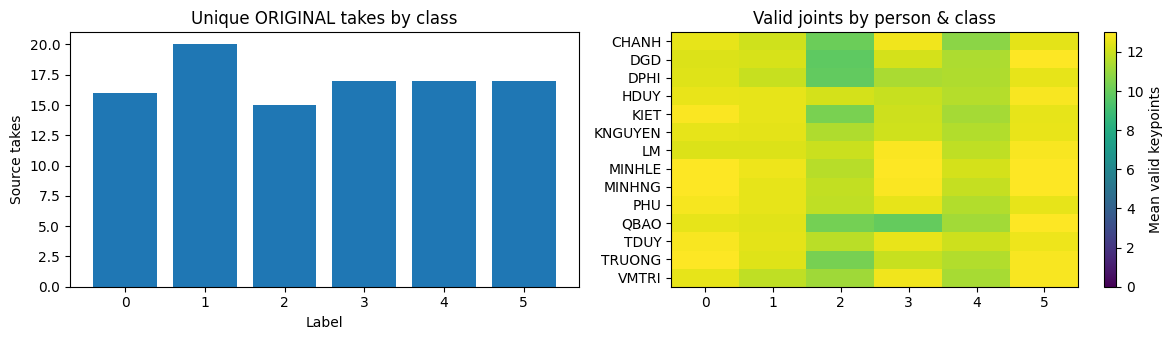

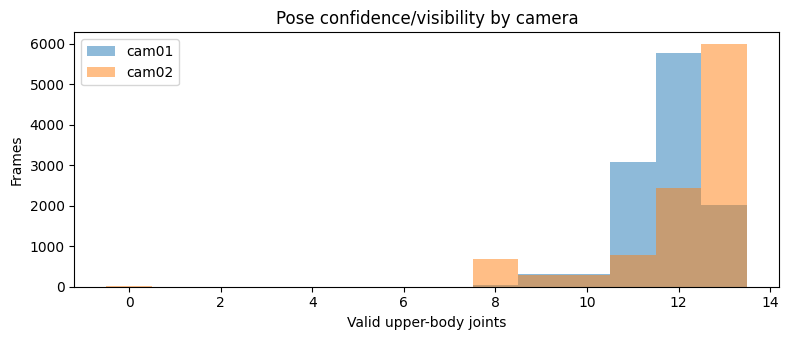

source_takes  frames  pose_frames
person_id label                                   
CHANH     0                 2     334          334
          1                 2     425          425
          2                 2     391          391
          3                 2     510          510
          4                 2     465          465
          5                 2     699          699
DGD       0                 1     477          477
          1                 1     688          688
          2                 1     747          747
          3                 1     207          207
          4                 1     342          342
          5                 1     364          364
DPHI      0                 1     651          651
          1                 1     620          620
          2                 1     794          785
          3                 2     675          675
          4                 1     826          826
          5                 2     682          682
HDUY      0                 2     229          229
          1                 1      96           96
          2                 1     108          108
          3                 1     140          140
          4                 1     144          144
          5                 1     148          148
KIET      0                 1     151          151
          1                 1     160          160
          2                 1     143          143
          3                 1     142          142
          4                 1     223          223
          5                 1     140          140

15958

In [4]:
import matplotlib.pyplot as plt
CHARTS=RAW_REPORT/'charts';CHARTS.mkdir(exist_ok=True)
summary={'source_zip_sha256':SOURCE_SHA,'dataset_filename':RAW_ZIP.name,
 'clips':int(len(catalog)),'exported_takes':int(catalog.drop_duplicates(['person_id','session_id','label','take_id']).shape[0]),
 'source_takes':int(catalog.source_group_id.nunique()),'people':int(catalog.person_id.nunique()),
 'frames':int(catalog.frames.sum()),'pose_frames':int(catalog.pose17_frames.sum()),
 'none13_frames':int(catalog.none13_frames.sum()),'full13_frames':int(catalog.full13_frames.sum()),
 'split':split_info,'issues':audit['issues']}
def saveplot(filename):
    plt.tight_layout();plt.savefig(CHARTS/filename,dpi=140,bbox_inches='tight');plt.show();plt.close()
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
counts=catalog.drop_duplicates('source_group_id').label.value_counts().reindex(LABELS,fill_value=0)
ax[0].bar(list(LABELS),counts);ax[0].set(title='Unique ORIGINAL takes by class',xlabel='Label',ylabel='Source takes')
q=frame_quality.groupby(['person_id','label']).valid13_count.mean().unstack().reindex(columns=LABELS)
im=ax[1].imshow(q.to_numpy(),aspect='auto',vmin=0,vmax=13)
ax[1].set(yticks=range(len(q)),yticklabels=q.index,xticks=range(6),xticklabels=list(LABELS),title='Valid joints by person & class')
fig.colorbar(im,ax=ax[1],label='Mean valid keypoints');saveplot('01_counts_quality.png')
fig,ax=plt.subplots(figsize=(8,3.5))
for camera,part in frame_quality.groupby('camera_id'):
    ax.hist(part.valid13_count,bins=np.arange(15)-.5,alpha=.5,label=camera)
ax.legend();ax.set(xlabel='Valid upper-body joints',ylabel='Frames',title='Pose confidence/visibility by camera');saveplot('02_valid13_camera.png')
display(catalog.groupby(['person_id','label']).agg(source_takes=('source_group_id','nunique'),frames=('frames','sum'),pose_frames=('pose17_frames','sum')).head(30))
catalog.to_csv(RAW_REPORT/'raw_catalog.csv',index=False)
frame_quality.to_csv(RAW_REPORT/'raw_frame_quality.csv.gz',index=False,compression='gzip')
joint_coverage.to_csv(RAW_REPORT/'joint_coverage.csv',index=False)
split_df.to_csv(RAW_REPORT/'split_manifest.csv',index=False)
(RAW_REPORT/'raw_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
(RAW_REPORT/'curation_summary.json').write_text(json.dumps({k:v for k,v in curation.items() if k!='recordings'},indent=2,ensure_ascii=False))

## 5 — Review hình thực tế (tùy chọn)
Lấy một frame mỗi nhãn trong **train**, không dùng hình Test để thiết kế feature/augmentation. Bỏ qua cell này nếu chỉ cần EDA.

In [5]:
SHOW_REAL_VIDEO = False  # True khi cần đối chiếu raw; OpenCV + MP4 đọc từ ZIP, không ghi Drive
if SHOW_REAL_VIDEO:
    import cv2
    import tempfile
    with zipfile.ZipFile(LOCAL_ZIP) as z:
        prefix=next(n[:-len('labels.csv')] for n in z.namelist() if n.endswith('Real_Posture_Dataset/labels.csv'))
        fig,axes=plt.subplots(2,3,figsize=(12,8))
        for label,ax in enumerate(axes.flat):
            subset=catalog[(catalog.label==label)&(catalog.person_id.isin(split_info['train_people']))]
            item=subset.sort_values('full13_rate',ascending=False).iloc[0]
            with tempfile.NamedTemporaryFile(suffix='.mp4') as tmp:
                tmp.write(z.read(prefix+item.video_path));tmp.flush()
                capture=cv2.VideoCapture(tmp.name)
                f=int(item.frames)//2;capture.set(cv2.CAP_PROP_POS_FRAMES,f)
                ok,bgr=capture.read();capture.release()
                if ok: ax.imshow(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))
                else: ax.text(.5,.5,'decode failed',ha='center')
            ax.set_title(f'L{label}: {item.person_id} / {item.camera_id}');ax.axis('off')
        saveplot('03_real_train_frames.png')

## 6 — Review ZIP nhỏ (không có video/raw17)
Tải file này để phân tích chất lượng và xác nhận split trước Notebook 02.

In [6]:
review=refresh_review_zip(BASE)
print('[PASS] Notebook 01 |',RAW_REPORT,'| REVIEW:',review)


[PASS] Notebook 01 | /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/raw | REVIEW: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/review.zip
